In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('scored.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  16 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error
0,769,2942669846,"Reinforcement learning usually makes use of numerical rewards, which have nice properties but also come with drawbacks and difficulties. Using rewards on an ordinal scale (ordinal rewards) is an alternative to numerical rewards that has received more attention in recent years. In this paper, a general approach to adapting reinforcement learning problems to the use of ordinal rewards is presented and motivated. We show how to convert common reinforcement learning algorithms to an ordinal variation by the example of Q-learning and introduce Ordinal Deep Q-Networks, which adapt deep reinforcement learning to ordinal rewards. Additionally, we run evaluations on problems provided by the OpenAI Gym framework, showing that our ordinal variants exhibit a performance that is comparable to the numerical variations for a number of problems. We also give first evidence that our ordinal variant is able to produce better results for problems with less engineered and simpler-to-design reward signals.","This paper presents a novel approach to deep reinforcement learning that combines the ideas from ""Playing Atari with Deep Reinforcement Learning"" and ""Quantile Reinforcement Learning"". The proposed method uses a convolutional neural network to estimate the value function directly from raw sensory input, and applies stochastic approximation with two timescales to evaluate policies based on quantiles. The effectiveness of the approach is demonstrated through experiments on the General Video Game Playing framework, where it outperforms existing algorithms in terms of both accuracy and performance. Furthermore, the paper addresses the issue of overestimation in action values, as discussed in ""Deep Reinforcement Learning with Double Q-Learning"", by proposing a modified version of the DQN algorithm that reduces such overestimations and improves overall performance.",0.3709,0.0659,0.1818,0.8458,0.8438,0.8448,2.0,7.0,7.0,4,False
1,2012,2913127348,"Gatherings of thousands to millions of people frequently occur for an enormous variety of events, and automated counting of these high-density crowds is useful for safety, management, and measuring significance of an event. In this work, we show that the regularly accepted labeling scheme of crowd density maps for training deep neural networks is less effective than our alternative inverse k-nearest neighbor (i$k$NN) maps, even when used directly in existing state-of-the-art network structures. We also provide a new network architecture MUD-i$k$NN, which uses multi-scale upsampling via transposed convolutions to take full advantage of the provided i$k$NN labeling. This upsampling combined with the i$k$NN maps further improves crowd counting accuracy. Our new network architecture performs favorably in comparison with the state-of-the-art. However, our labeling and upsampling techniques are generally applicable to existing crowd counting architectures.","This paper presents a novel deep convolutional encoder decoder architecture for image segmentation, called SegNet, which consists of an encoder network, a corresponding decoder network followed by a pixel-wise classification layer. The architecture of the encoder network is topologically identical to the 13 convolutional layers in the VGG16 network. The decoder network maps the low resolution encoder feature maps to full input resolution feature maps for pixel-wise classification. The novelty of SegNet lies in the manner in which the decoder upsamples its lower resolution input feature map(s). Specifically, the decoder uses pooling indices computed in the max-pooling step of the corresponding encoder to perform non-linear upsampling. This eliminates the need for learning to upsample. The upsampled maps are sparse and are then convolved with trainable filter

In [12]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

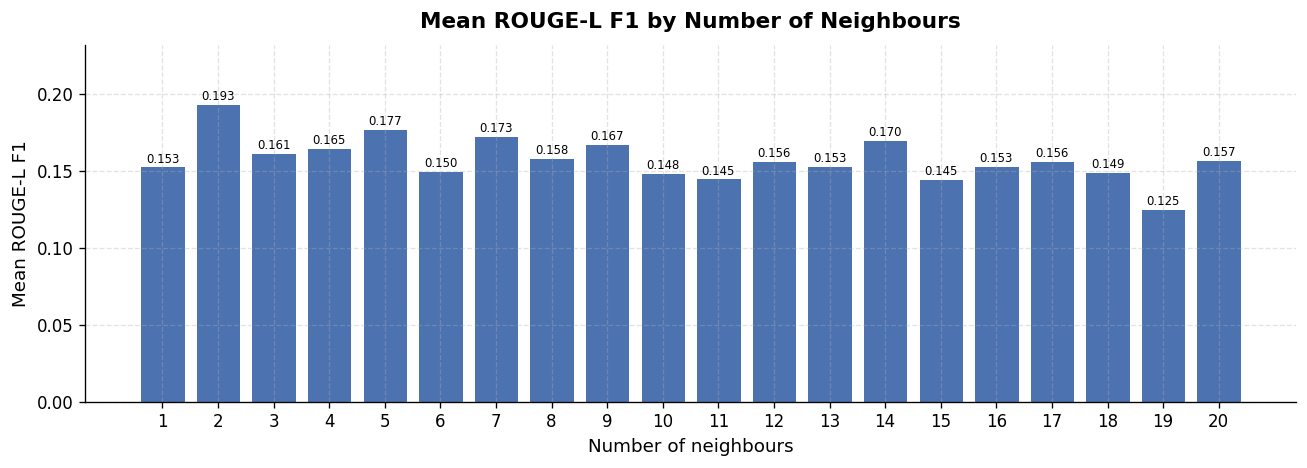

In [13]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

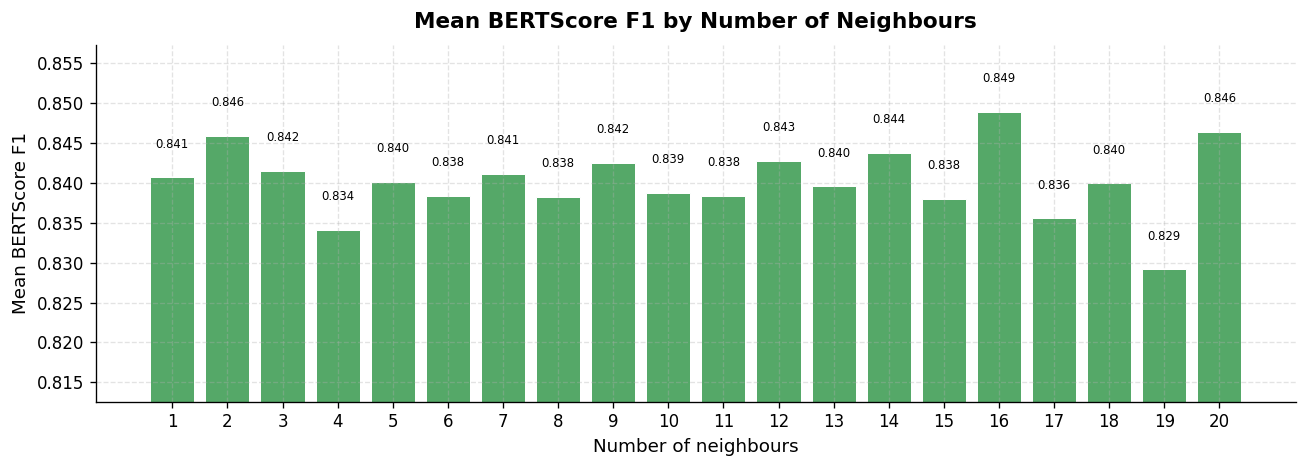

In [14]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

Overall mean LLM accuracy: 2.598
Successfully generated (non-error): 184 / 200


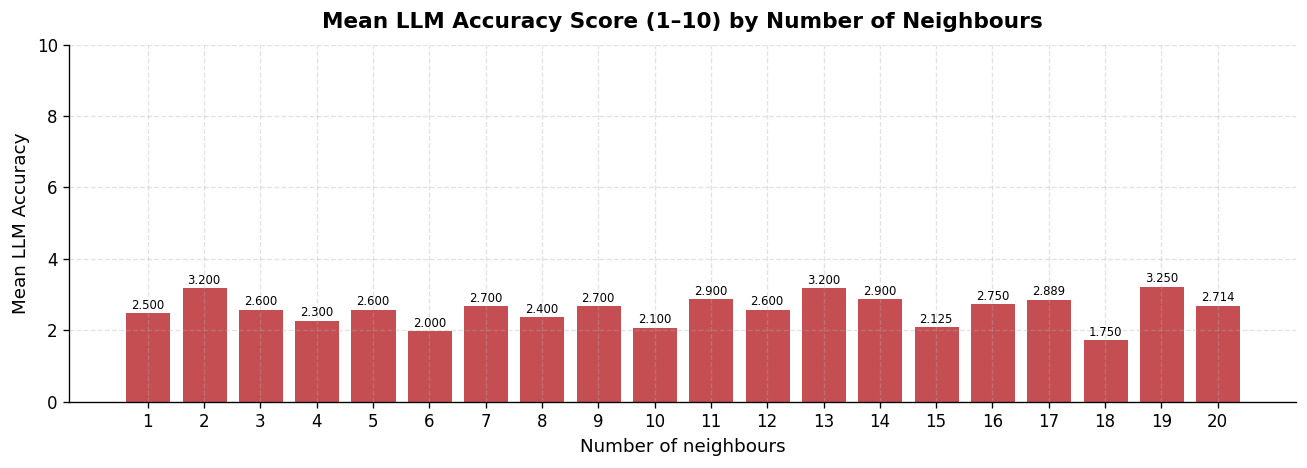

In [15]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
overall_acc_mean = df['llm_accuracy'].mean()
num_successful = (~df['is_error']).sum()
print(f'Overall mean LLM accuracy: {overall_acc_mean:.3f}')
print(f'Successfully generated (non-error): {num_successful} / {len(df)}')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

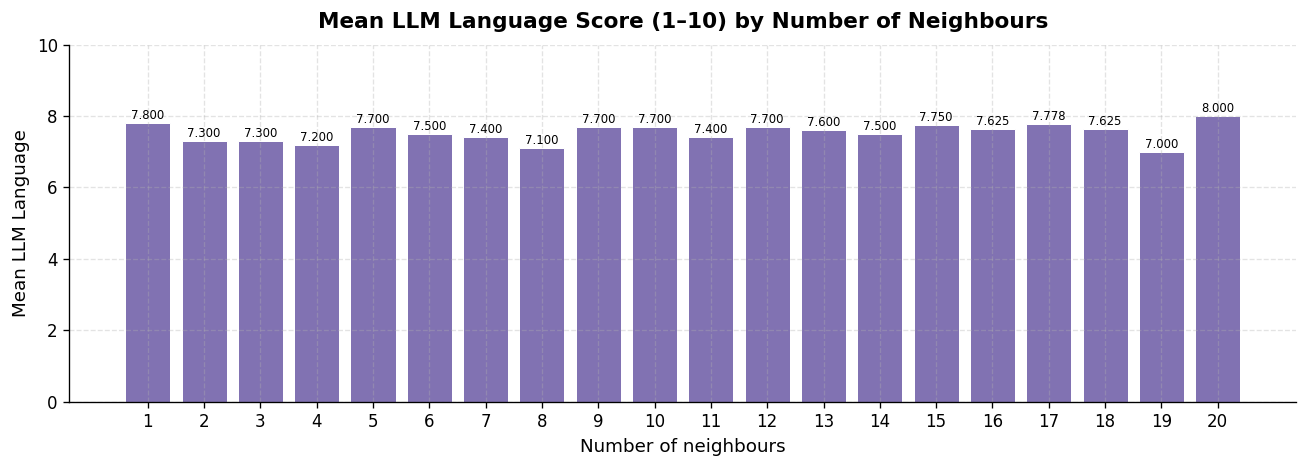

In [16]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

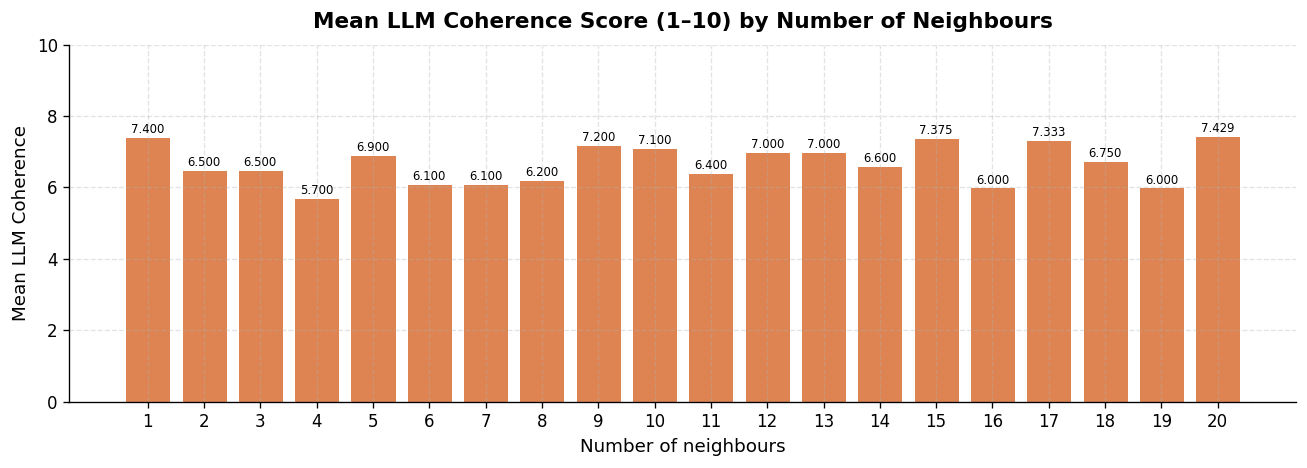

In [17]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

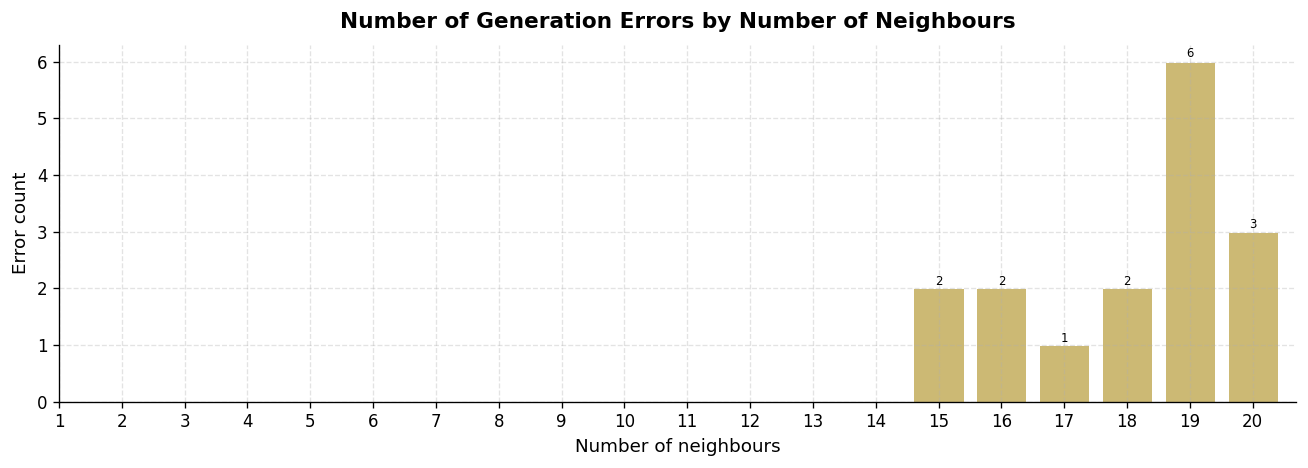

In [18]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [19]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_39301/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,45084,"This paper presents a deep reinforcement learning algorithm for online accompaniment generation, with potential for real-time interactive human-machine duet improvisation. Different from offline music generation and harmonization, online music accompaniment requires the algorithm to respond to human input and generate the machine counterpart in a sequential order. We cast this as a reinforcement learning problem, where the generation agent learns a policy to generate a musical note (action) based on previously generated context (state). The key of this algorithm is the well-functioning reward model. Instead of defining it using music composition rules, we learn this model from monophonic and polyphonic training data. This model considers the compatibility of the machine-generated note with both the machine-generated context and the human-generated context. Experiments show that this algorithm is able to respond to the human part and generate a melodic, harmonic and diverse machine part. Subjective evaluations on preferences show that the proposed algorithm generates music pieces of higher quality than the baseline method.","This paper presents a novel approach to sequence level training in natural language processing (NLP) that combines recurrent neural networks (RNNs) with actor-critic methods from reinforcement learning (RL). The proposed method, called SequenceGAN, directly optimizes a task-specific score such as BLEU during training, leading to improved performance on both synthetic and real-world NLP tasks. The method leverages RL techniques in the supervised learning setting, conditioning the critic network on the ground-truth output, bypassing the discrepancy between training and testing modes. The analysis paves the way for similar methods to be applied in other NLP tasks, such as machine translation, caption generation, and dialogue modeling.",1.0
1,22304,"We develop a novel technique to determine call provenance in anonymous VoIP communications using acoustic side-channels. The technique exploits location-attributable information embedded within audio speech data. The victim's speech is exploited as an excitation signal, which is modulated (acted upon) by the acoustic reflection characteristics of the victim's location. We show that leading VoIP communication channels faithfully transfer this information between sender-receiver pairs, enabling passive receivers to extract a location fingerprint, to establish call provenance. To establish provenance, a fingerprint is compared against a database of labelled fingerprints to identify a match. The technique is fully passive and does not depend on any characteristic background sounds, is speaker independent, and is robust to lossy network conditions. Evaluation using a corpus of recordings of VoIP conversations, over the Tor network, confirms that recording locations can be fingerprinted and detected remotely with low false-positive rate.","This paper presents a new application of covert acoustical mesh networks in air, which utilize audio modulation/demodulation to exchange data between different computing systems over the air medium. The communication system is adapted from a robust underwater communication system and utilizes the ultrasonic frequency range to establish covert and stealthy communications. The paper demonstrates the extension of covert acoustical communication to multi-hop communications and wireless mesh networks, creating a meshed botnet or malnet accessible via inaudible audio transmissions. The paper also explores various applications of covert acoustical mesh networks, such as remote keylogging over multiple hops, and discusses countermeasures against them, including lowpass filtering in computing systems and a host-based intrusion detection system.",1.0
2,82788,"In this paper, we treat the image generation task using the autoencoder, a representative latent model. Unlike many studie

In [20]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


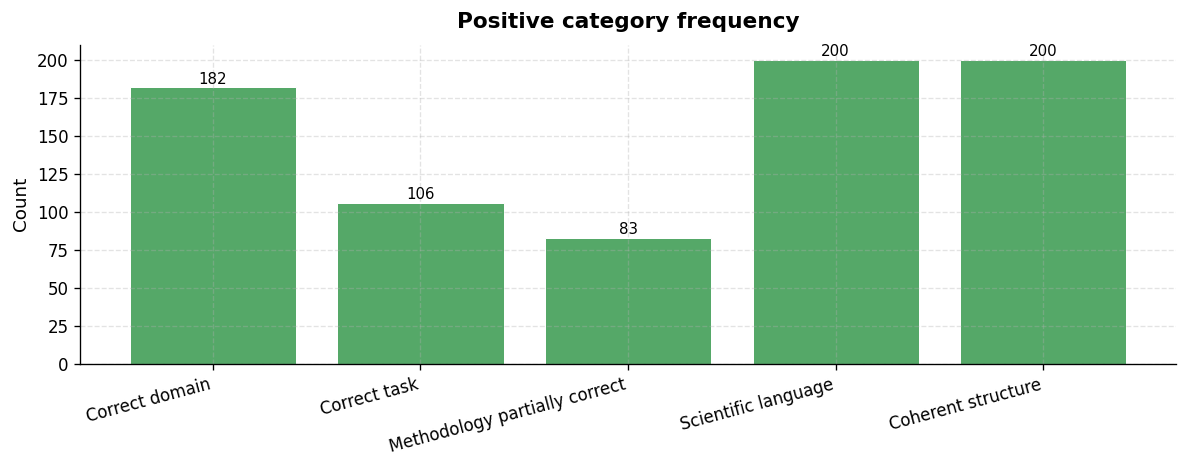

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()